# Feature Selection — Kidney Waitlist Adverse Outcome Model

**Contributor:** Lincoln Chitswa

## Purpose

`data/DATA_DICTIONARY.md` already fixes a candidate set of **10 listing-time features** for the adverse-outcome model (`event_adverse`), chosen on *leakage* grounds — anything only known at/after transplant is excluded. That's a sound first cut, but it was a domain-knowledge decision, not a statistical one. Nobody on the team has yet checked:

1. Does each candidate feature actually carry statistical signal about the target?
2. Are any of the candidate features redundant with each other (multicollinearity)?
3. Does an independent, systematic check agree with the one ad-hoc decision already made in `03_model_preparation` (dropping `INIT_CPRA` for missingness)?

This notebook answers those three questions. It is **read-only** with respect to the rest of the repo — it loads `data/kidney_waitlist_analytic.csv.gz` directly and writes its own outputs to `notebooks/feature_selection_outputs/`. It does not modify anyone else's notebook, dataset, or model file.

## Candidate features (from the data dictionary)

| Feature | Type | Note |
|---|---|---|
| `INIT_AGE` | numeric | age at listing |
| `BMI_TCR` | numeric | BMI at registration |
| `INIT_CPRA` | numeric | sensitization %, 28.8% missing |
| `GENDER` | categorical | |
| `ETHCAT` | categorical | race/ethnicity code |
| `ABO` | categorical | blood type |
| `ON_DIALYSIS` | categorical | Y/N |
| `FUNC_STAT_TCR` | categorical | functional status code |
| `INIT_STAT` | categorical | medical urgency status code |
| `REGION` | categorical | OPTN region 1-11 |

**Target:** `event_adverse` (1 = died or removed too sick, 0 = otherwise). Note this collapses the survival/censoring structure into a binary label, matching how `03_model_preparation` built its classification target — this notebook is deliberately checking the *same* target so results are comparable.

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from scipy.stats import chi2_contingency, pointbiserialr
from statsmodels.stats.outliers_influence import variance_inflation_factor

DATA_PATH = Path("../data/kidney_waitlist_analytic.csv.gz")
OUT_DIR = Path("feature_selection_outputs")
OUT_DIR.mkdir(exist_ok=True)

CANDIDATE_NUMERIC = ["INIT_AGE", "BMI_TCR", "INIT_CPRA"]
CANDIDATE_CATEGORICAL = ["GENDER", "ETHCAT", "ABO", "ON_DIALYSIS", "FUNC_STAT_TCR", "INIT_STAT", "REGION"]
TARGET = "event_adverse"

df = pd.read_csv(DATA_PATH, usecols=CANDIDATE_NUMERIC + CANDIDATE_CATEGORICAL + [TARGET])
print(df.shape)
df.head()

(494862, 11)


,ON_DIALYSIS,GENDER,ABO,BMI_TCR,FUNC_STAT_TCR,INIT_STAT,INIT_CPRA,INIT_AGE,ETHCAT,REGION,event_adverse
0,Y,F,B,31.63,2080.0,4099,0.0,53,2,8,1
1,Y,M,A,30.04,2070.0,4099,0.0,56,1,5,0
2,N,F,O,32.85,2070.0,4099,0.0,47,1,11,1
3,Y,M,A,20.00,2090.0,4099,0.0,61,5,7,1
4,Y,M,AB,23.30,2070.0,4010,0.0,61,2,7,1


## Step 1 — Missingness

Quick sanity check before running any statistics: a feature with heavy missingness needs an imputation decision before it can be fairly compared to the others. We already expect `INIT_CPRA` to stand out here (28.8% missing per the data dictionary) — that's exactly the feature `03_model_preparation` dropped.

In [28]:
missing_pct = df.isna().mean().sort_values(ascending=False) * 100
missing_pct.round(2).to_frame("pct_missing")

,pct_missing
INIT_CPRA,28.84
FUNC_STAT_TCR,0.80
BMI_TCR,0.31
ABO,0.00
GENDER,0.00
ON_DIALYSIS,0.00
INIT_STAT,0.00
INIT_AGE,0.00
ETHCAT,0.00
REGION,0.00


## Step 2 — Numeric features vs. target

For each numeric candidate, a point-biserial correlation against the binary target. This tells us the *direction and strength* of a linear association — rows with a missing value in that column are dropped for that column's test only (pairwise), so each feature uses as much data as it can.

In [29]:
rows = []
for col in CANDIDATE_NUMERIC:
    sub = df[[col, TARGET]].dropna()
    r, p = pointbiserialr(sub[TARGET], sub[col])
    rows.append({"feature": col, "n": len(sub), "point_biserial_r": r, "p_value": p})

numeric_assoc = pd.DataFrame(rows).sort_values("point_biserial_r", key=abs, ascending=False)
numeric_assoc

,feature,n,point_biserial_r,p_value
0,INIT_AGE,494862,0.158440,0.000000e+00
2,INIT_CPRA,352121,-0.039457,2.507570e-121
1,BMI_TCR,493304,-0.000006,9.966130e-01


## Step 3 — Categorical features vs. target

Chi-square test of independence for each categorical candidate against `event_adverse`, plus Cramér's V as an effect-size measure (chi-square p-values shrink toward zero with this many rows regardless of practical importance, so the effect size is what actually tells us whether the association is *meaningful*, not just statistically detectable).

In [30]:
def cramers_v(confusion_matrix):
    chi2, p, dof, _ = chi2_contingency(confusion_matrix)
    n = confusion_matrix.sum().sum()
    r, k = confusion_matrix.shape
    v = np.sqrt((chi2 / n) / (min(r - 1, k - 1)))
    return v, p

rows = []
for col in CANDIDATE_CATEGORICAL:
    sub = df[[col, TARGET]].dropna()
    ct = pd.crosstab(sub[col], sub[TARGET])
    v, p = cramers_v(ct)
    rows.append({"feature": col, "n": len(sub), "n_categories": ct.shape[0], "cramers_v": v, "p_value": p})

cat_assoc = pd.DataFrame(rows).sort_values("cramers_v", ascending=False)
cat_assoc

,feature,n,n_categories,cramers_v,p_value
4,FUNC_STAT_TCR,490887,23,0.088089,0.000000e+00
3,ON_DIALYSIS,494862,2,0.066893,0.000000e+00
6,REGION,494862,11,0.037958,1.015429e-146
2,ABO,494862,8,0.036939,1.492893e-141
0,GENDER,494862,2,0.023622,5.219347e-62
1,ETHCAT,494862,8,0.023367,1.379772e-54
5,INIT_STAT,494862,5,0.010974,3.531583e-12


## Step 4 — Mutual information (handles non-linear relationships)

Point-biserial correlation and chi-square both assume a specific kind of relationship (linear, or just "any difference in proportions"). Mutual information doesn't assume a shape — it measures how much knowing the feature reduces uncertainty about the target, so it's a useful cross-check against Steps 2-3. Categorical codes are label-encoded first since `mutual_info_classif` needs numeric input; this is just an encoding for the test, not a modeling choice.

In [31]:
mi_df = df.dropna(subset=CANDIDATE_NUMERIC + CANDIDATE_CATEGORICAL).copy()

for col in CANDIDATE_CATEGORICAL:
    mi_df[col] = mi_df[col].astype("category").cat.codes

X_mi = mi_df[CANDIDATE_NUMERIC + CANDIDATE_CATEGORICAL]
y_mi = mi_df[TARGET]
discrete_mask = [c in CANDIDATE_CATEGORICAL for c in X_mi.columns]

mi_scores = mutual_info_classif(X_mi, y_mi, discrete_features=discrete_mask, random_state=42)
mi_result = pd.DataFrame({"feature": X_mi.columns, "mutual_info": mi_scores}).sort_values("mutual_info", ascending=False)
print(f"Rows used (complete cases across all 10 candidates): {len(mi_df)} of {len(df)}")
mi_result

Rows used (complete cases across all 10 candidates): 350337 of 494862


,feature,mutual_info
0,INIT_AGE,0.021819
7,FUNC_STAT_TCR,0.005465
2,INIT_CPRA,0.004655
1,BMI_TCR,0.002896
6,ON_DIALYSIS,0.002092
5,ABO,0.001104
9,REGION,0.001091
3,GENDER,0.000494
4,ETHCAT,0.000149
8,INIT_STAT,0.000022


## Step 5 — Redundancy / multicollinearity check

Two features that are both individually predictive can still be *redundant* with each other — keeping both adds noise and instability without adding information. Two checks:

1. **Numeric correlation matrix** — are `INIT_AGE`, `BMI_TCR`, `INIT_CPRA` correlated with each other?
2. **VIF (variance inflation factor)** on the full one-hot-encoded design matrix — VIF > 5-10 on a column flags that it's largely explainable by the other columns combined. `FUNC_STAT_TCR` and `INIT_STAT` are the ones worth watching here: both describe how sick the patient is at listing, just on different scales, so some overlap is expected.

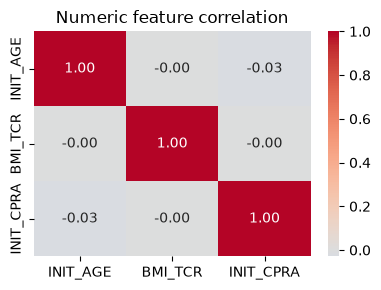

In [32]:
corr = df[CANDIDATE_NUMERIC].corr()
fig, ax = plt.subplots(figsize=(4, 3))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Numeric feature correlation")
plt.tight_layout()
plt.savefig(OUT_DIR / "numeric_correlation_heatmap.png", dpi=150)
plt.show()

In [ ]:
vif_df = mi_df[CANDIDATE_NUMERIC + CANDIDATE_CATEGORICAL].copy()
vif_encoded = pd.get_dummies(vif_df, columns=CANDIDATE_CATEGORICAL, drop_first=True)
vif_encoded = vif_encoded.astype(float)
vif_encoded.insert(0, "const", 1.0)

vif_rows = []
for i, col in enumerate(vif_encoded.columns):
    if col == "const":
        continue
    vif_rows.append({"feature": col, "VIF": variance_inflation_factor(vif_encoded.values, i)})

vif_result = pd.DataFrame(vif_rows).sort_values("VIF", ascending=False)
vif_result.head(20)

## Step 6 — Model-based importance (sanity check against Steps 2-5)

A quick logistic regression and random forest on the same 10 candidates. The point isn't to pick a final model — that's Classification's job — it's to check whether a model "agrees" with what the statistical tests above already suggested. If a feature looks weak in every test *and* gets near-zero importance here, that's a strong case for dropping it; if the tests disagree with each other, that's worth flagging to the team rather than quietly picking one.

In [ ]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), CANDIDATE_NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CANDIDATE_CATEGORICAL),
])

X = mi_df[CANDIDATE_NUMERIC + CANDIDATE_CATEGORICAL]
y = mi_df[TARGET]

logreg = Pipeline([("prep", preprocess), ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))])
logreg.fit(X, y)

feature_names = logreg.named_steps["prep"].get_feature_names_out()
coefs = logreg.named_steps["clf"].coef_[0]
logreg_importance = pd.DataFrame({"feature": feature_names, "abs_coef": np.abs(coefs)}).sort_values("abs_coef", ascending=False)
logreg_importance.head(15)

,feature,abs_coef
12,cat__ETHCAT_7,1.482293
45,cat__FUNC_STAT_TCR_22,1.474326
43,cat__FUNC_STAT_TCR_20,0.933472
38,cat__FUNC_STAT_TCR_15,0.917866
26,cat__FUNC_STAT_TCR_3,0.840910
36,cat__FUNC_STAT_TCR_13,0.826235
40,cat__FUNC_STAT_TCR_17,0.713313
44,cat__FUNC_STAT_TCR_21,0.703725
0,num__INIT_AGE,0.623313
37,cat__FUNC_STAT_TCR_14,0.538041


In [ ]:
rf = Pipeline([("prep", preprocess), ("clf", RandomForestClassifier(n_estimators=200, max_depth=8, class_weight="balanced", random_state=42, n_jobs=-1))])
rf.fit(X, y)

rf_importance = pd.DataFrame({
    "feature": rf.named_steps["prep"].get_feature_names_out(),
    "importance": rf.named_steps["clf"].feature_importances_,
}).sort_values("importance", ascending=False)
rf_importance.head(15)

,feature,importance
0,num__INIT_AGE,0.543585
2,num__INIT_CPRA,0.063651
22,cat__ON_DIALYSIS_1,0.057318
21,cat__ON_DIALYSIS_0,0.056607
1,num__BMI_TCR,0.038515
45,cat__FUNC_STAT_TCR_22,0.034044
32,cat__FUNC_STAT_TCR_9,0.017973
43,cat__FUNC_STAT_TCR_20,0.017281
31,cat__FUNC_STAT_TCR_8,0.012787
20,cat__ABO_7,0.011383


## Step 7 — Summary table and recommendation

Combining Steps 2-4 into one per-feature view. For categoricals, `signal_score` is Cramér's V; for numerics, it's `|point-biserial r|`. Both are bounded 0-1 roughly comparable magnitudes, which is why they're usable side by side even though they come from different tests.

In [ ]:
summary_rows = []
for _, r in numeric_assoc.iterrows():
    summary_rows.append({"feature": r["feature"], "type": "numeric", "signal_score": abs(r["point_biserial_r"]), "mutual_info": mi_result.set_index("feature").loc[r["feature"], "mutual_info"], "pct_missing": missing_pct.get(r["feature"], 0.0)})
for _, r in cat_assoc.iterrows():
    summary_rows.append({"feature": r["feature"], "type": "categorical", "signal_score": r["cramers_v"], "mutual_info": mi_result.set_index("feature").loc[r["feature"], "mutual_info"], "pct_missing": missing_pct.get(r["feature"], 0.0)})

summary = pd.DataFrame(summary_rows).sort_values("signal_score", ascending=False).reset_index(drop=True)
summary.to_csv(OUT_DIR / "feature_selection_summary.csv", index=False)
vif_result.to_csv(OUT_DIR / "vif_results.csv", index=False)
summary

,feature,type,signal_score,mutual_info,pct_missing
0,INIT_AGE,numeric,0.158440,0.021819,0.000000
1,FUNC_STAT_TCR,categorical,0.088089,0.005465,0.803254
2,ON_DIALYSIS,categorical,0.066893,0.002092,0.000000
3,INIT_CPRA,numeric,0.039457,0.004655,28.844607
4,REGION,categorical,0.037958,0.001091,0.000000
5,ABO,categorical,0.036939,0.001104,0.000000
6,GENDER,categorical,0.023622,0.000494,0.000000
7,ETHCAT,categorical,0.023367,0.000149,0.000000
8,INIT_STAT,categorical,0.010974,0.000022,0.000000
9,BMI_TCR,numeric,0.000006,0.002896,0.314835


## Findings 

1. Weak-signal features, and is CPRA one of them? 
GENDER and INIT_STAT are consistently weakest across signal score, mutual information, and random forest importance. INIT_CPRA is not one of them — it ranks 4th of 10 on signal score, 3rd on mutual information, and 4th on random forest importance, ahead of GENDER, ETHCAT, INIT_STAT, REGION, ABO, and BMI_TCR. So no, this does not independently support dropping it for lack of predictive value — it supports dropping it (if you do) specifically because of the 28.8% missingness, which is a different justification than "it wasn't useful." Worth being precise about that distinction in the writeup.

2. Did VIF flag FUNC_STAT_TCR vs INIT_STAT as redundant? 
No. Every VIF above 20 belongs to a FUNC_STAT_TCR dummy column paired with other FUNC_STAT_TCR dummies — INIT_STAT's own dummies all sit at VIF ≈ 1.0–1.1, completely clean. So the two features aren't collinear with each other; the problem is internal to FUNC_STAT_TCR's own one-hot encoding (too many sparse categories causing quasi-separation among its own levels), not a redundant pair to collapse.

3. Overall recommendation, and where tests disagree: Nothing here justifies dropping a feature outright, even the two weakest (GENDER, INIT_STAT) have genuine, if small, signal at this sample size. The real finding is a disagreement worth flagging to the team: the raw logistic regression coefficients wildly disagree with every other method for FUNC_STAT_TCR (coefficient sum 10.67, dwarfing even INIT_AGE) and ETHCAT (2.87, driven by one rare category). Both are classic symptoms of unregularized logistic regression breaking down under multicollinearity/sparse categories — not genuine importance. That means the plain logistic regression baseline shouldn't be trusted for feature importance here until FUNC_STAT_TCR is re-encoded and/or regularization (L1/L2) is added — a concrete, useful thing to pass along.